In [ ]:
import pandas as pd
df=pd.read_csv("/customer_shopping_behavior.csv")
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [ ]:
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [ ]:
df.isnull().sum()

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [ ]:
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x: x.fillna(x.median()))

In [ ]:
df.isnull().sum()

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [ ]:
df.columns = [col.lower().replace(' ', '_') for col in df.columns]
df = df.rename(columns={'purchase_amount_(usd)': 'purchase_amount'})

In [ ]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

In [ ]:
# Create an age group column by splitting ages into four equal-sized groups
labels = ['Young adult', 'Adult', 'Middle-aged', 'Senior']
df['age_group'] = pd.qcut(df['age'], q=4, labels=labels)

In [ ]:
df[['age','age_group']].head(10)

,age,age_group
0,55,Middle-aged
1,19,Young adult
2,50,Middle-aged
3,21,Young adult
4,45,Middle-aged
5,46,Middle-aged
6,63,Senior
7,27,Young adult
8,26,Young adult
9,57,Middle-aged


In [ ]:
#Map textual purchase frequencies to numeric days for easier calculation
frequency_mapping = {
    'Weekly': 7,
    'Fortnightly': 14,
    'Bi-Weekly': 14,
    'Monthly': 30,
    'Quarterly': 90,
    'Every 3 Months': 90,
    'Annually': 365
}

df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)

In [ ]:
df[['purchase_frequency_days','frequency_of_purchases']].head(10)

,purchase_frequency_days,frequency_of_purchases
0,14.0,Fortnightly
1,14.0,Fortnightly
2,7.0,Weekly
3,7.0,Weekly
4,365.0,Annually
5,7.0,Weekly
6,90.0,Quarterly
7,7.0,Weekly
8,365.0,Annually
9,90.0,Quarterly


In [ ]:
df[['discount_applied','promo_code_used']].head(10)

,discount_applied,promo_code_used
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,Yes,Yes
5,Yes,Yes
6,Yes,Yes
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


In [ ]:
# Check if 'discount_applied' and 'promo_code_used' carry identical information
(df['discount_applied'] == df['promo_code_used']).all()

np.True_

In [ ]:
# Drop the redundant column
df = df.drop('promo_code_used', axis=1)

In [ ]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='object')

In [ ]:
from google.colab import files

df.to_csv('customer_shopping.csv', index=False)
files.download('customer_shopping.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.shape

(3900, 19)

In [ ]:
df.columns.tolist()

['customer_id',
 'age',
 'gender',
 'item_purchased',
 'category',
 'purchase_amount',
 'location',
 'size',
 'color',
 'season',
 'review_rating',
 'subscription_status',
 'shipping_type',
 'discount_applied',
 'previous_purchases',
 'payment_method',
 'frequency_of_purchases',
 'age_group',
 'purchase_frequency_days']

In [ ]:
df.to_csv('customer_shopping_clean.csv', index=False)

In [ ]:
from google.colab import files
files.download('customer_shopping_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Churn Prediction with Machine Learning

## Method
1. **Split first** — 80% train / 20% test, *before* any labelling, so the test customers are never seen during training.
2. **Label the training data** with a churn rule (infrequent buyer **and** thin purchase history). The thresholds are learned from the **training set only** and then applied unchanged to the test set.
3. **Unsupervised learning** (KMeans) — discover at-risk customer groups from behaviour with *no labels*.
4. **Supervised learning** — train classifiers on the labelled training set; evaluate on the held-out test customers.
5. **Reality check** — what can the model predict *without* the behavioural columns?
6. **Export** scored customers for SQL / Power BI.

> **How to read the results:** the churn label is built from purchase interval and purchase history, and those columns are also model inputs. So the supervised models will learn the rule almost perfectly. That shows the pipeline works and gives you a model that scores new customers automatically, but it is **not evidence that churn can be forecast from independent signals**. Section 8 tests that directly.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay, classification_report, silhouette_score,
                             precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# Reuse `df` from the cleaning cells above. If you open this notebook fresh, load the cleaned CSV instead.
try:
    df
except NameError:
    for path in ['customer_shopping_clean.csv', 'customer_shopping.csv']:
        try:
            df = pd.read_csv(path)
            break
        except FileNotFoundError:
            continue
    else:
        raise FileNotFoundError('Run the cleaning cells above, or place customer_shopping_clean.csv next to this notebook.')

df = df.copy()

# Complete frequency mapping (the original cell missed 'Bi-Weekly' and 'Every 3 Months' -> 1,131 NaNs)
freq_map = {'Weekly': 7, 'Fortnightly': 14, 'Bi-Weekly': 14, 'Monthly': 30,
            'Quarterly': 90, 'Every 3 Months': 90, 'Annually': 365}
df['purchase_frequency_days'] = df['frequency_of_purchases'].map(freq_map)

assert df['purchase_frequency_days'].notna().all(), 'Unmapped purchase frequency values'
assert df['customer_id'].is_unique, 'Expected one row per customer'
print(f'{df.shape[0]:,} customers, {df.shape[1]} columns')

3,900 customers, 19 columns


## 2. Train / test split (before any labelling)

In [2]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE)
train_df, test_df = train_df.copy(), test_df.copy()
print(f'Train: {len(train_df):,} customers   |   Test (held out): {len(test_df):,} customers')

Train: 3,120 customers   |   Test (held out): 780 customers


## 3. Label the training data
Churn rule: **purchase interval ≥ 90 days AND previous purchases ≤ the training-set median.**
The median comes from the training data only; the test set just receives the same cut-offs. Test labels are used **only to score the model**, never to train it.

In [3]:
# ---- Change these two values to change the churn definition ----
FREQ_DAYS_THRESHOLD = 90      # buys no more often than every N days
HISTORY_QUANTILE    = 0.50    # ...and has at most this quantile of previous purchases (learned on train)
# -----------------------------------------------------------------

history_cutoff = train_df['previous_purchases'].quantile(HISTORY_QUANTILE)

def churn_rule(d):
    return ((d['purchase_frequency_days'] >= FREQ_DAYS_THRESHOLD) &
            (d['previous_purchases'] <= history_cutoff)).astype(int)

train_df['churn'] = churn_rule(train_df)     # used for training
test_df['churn']  = churn_rule(test_df)      # used ONLY for evaluation

print(f'Rule: interval >= {FREQ_DAYS_THRESHOLD} days AND previous_purchases <= {history_cutoff:.0f}')
print(f'Train churn rate: {train_df.churn.mean():.1%}  ({train_df.churn.sum():,} of {len(train_df):,})')
print(f'Test  churn rate: {test_df.churn.mean():.1%}  ({test_df.churn.sum():,} of {len(test_df):,})')

Rule: interval >= 90 days AND previous_purchases <= 25
Train churn rate: 21.8%  (681 of 3,120)
Test  churn rate: 24.2%  (189 of 780)


## 4. Segment analysis (training data only)
Churn rate by segment with a chi-square test. A gap only matters if it is statistically significant.

In [4]:
train_df['rating_band'] = pd.cut(train_df['review_rating'], [0, 3, 3.5, 4, 4.5, 5], include_lowest=True)
train_df['amount_band'] = pd.cut(train_df['purchase_amount'], [0, 25, 50, 75, 100], include_lowest=True)

seg_cols = ['subscription_status', 'discount_applied', 'shipping_type', 'payment_method',
            'category', 'season', 'gender', 'age_group', 'rating_band', 'amount_band']

rows = []
for c in seg_cols:
    g = train_df.groupby(c, observed=True)['churn'].mean()
    p = chi2_contingency(pd.crosstab(train_df[c], train_df['churn']))[1]
    rows.append({'segment_column': c, 'lowest_churn_rate': g.min(), 'highest_churn_rate': g.max(),
                 'spread_pct_points': 100 * (g.max() - g.min()), 'chi2_p_value': p,
                 'significant_at_5pct': p < 0.05})
seg_summary = pd.DataFrame(rows).sort_values('chi2_p_value').reset_index(drop=True)
seg_summary.round(3)

,segment_column,lowest_churn_rate,highest_churn_rate,spread_pct_points,chi2_p_value,significant_at_5pct
0,age_group,0.187,0.239,5.250,0.046,True
1,season,0.194,0.239,4.499,0.070,False
2,discount_applied,0.210,0.229,1.852,0.233,False
3,gender,0.209,0.223,1.403,0.399,False
4,amount_band,0.207,0.257,5.029,0.413,False
5,subscription_status,0.216,0.224,0.758,0.686,False
6,payment_method,0.194,0.229,3.542,0.753,False
7,category,0.209,0.238,2.867,0.755,False
8,shipping_type,0.202,0.229,2.697,0.883,False
9,rating_band,0.211,0.226,1.501,0.946,False


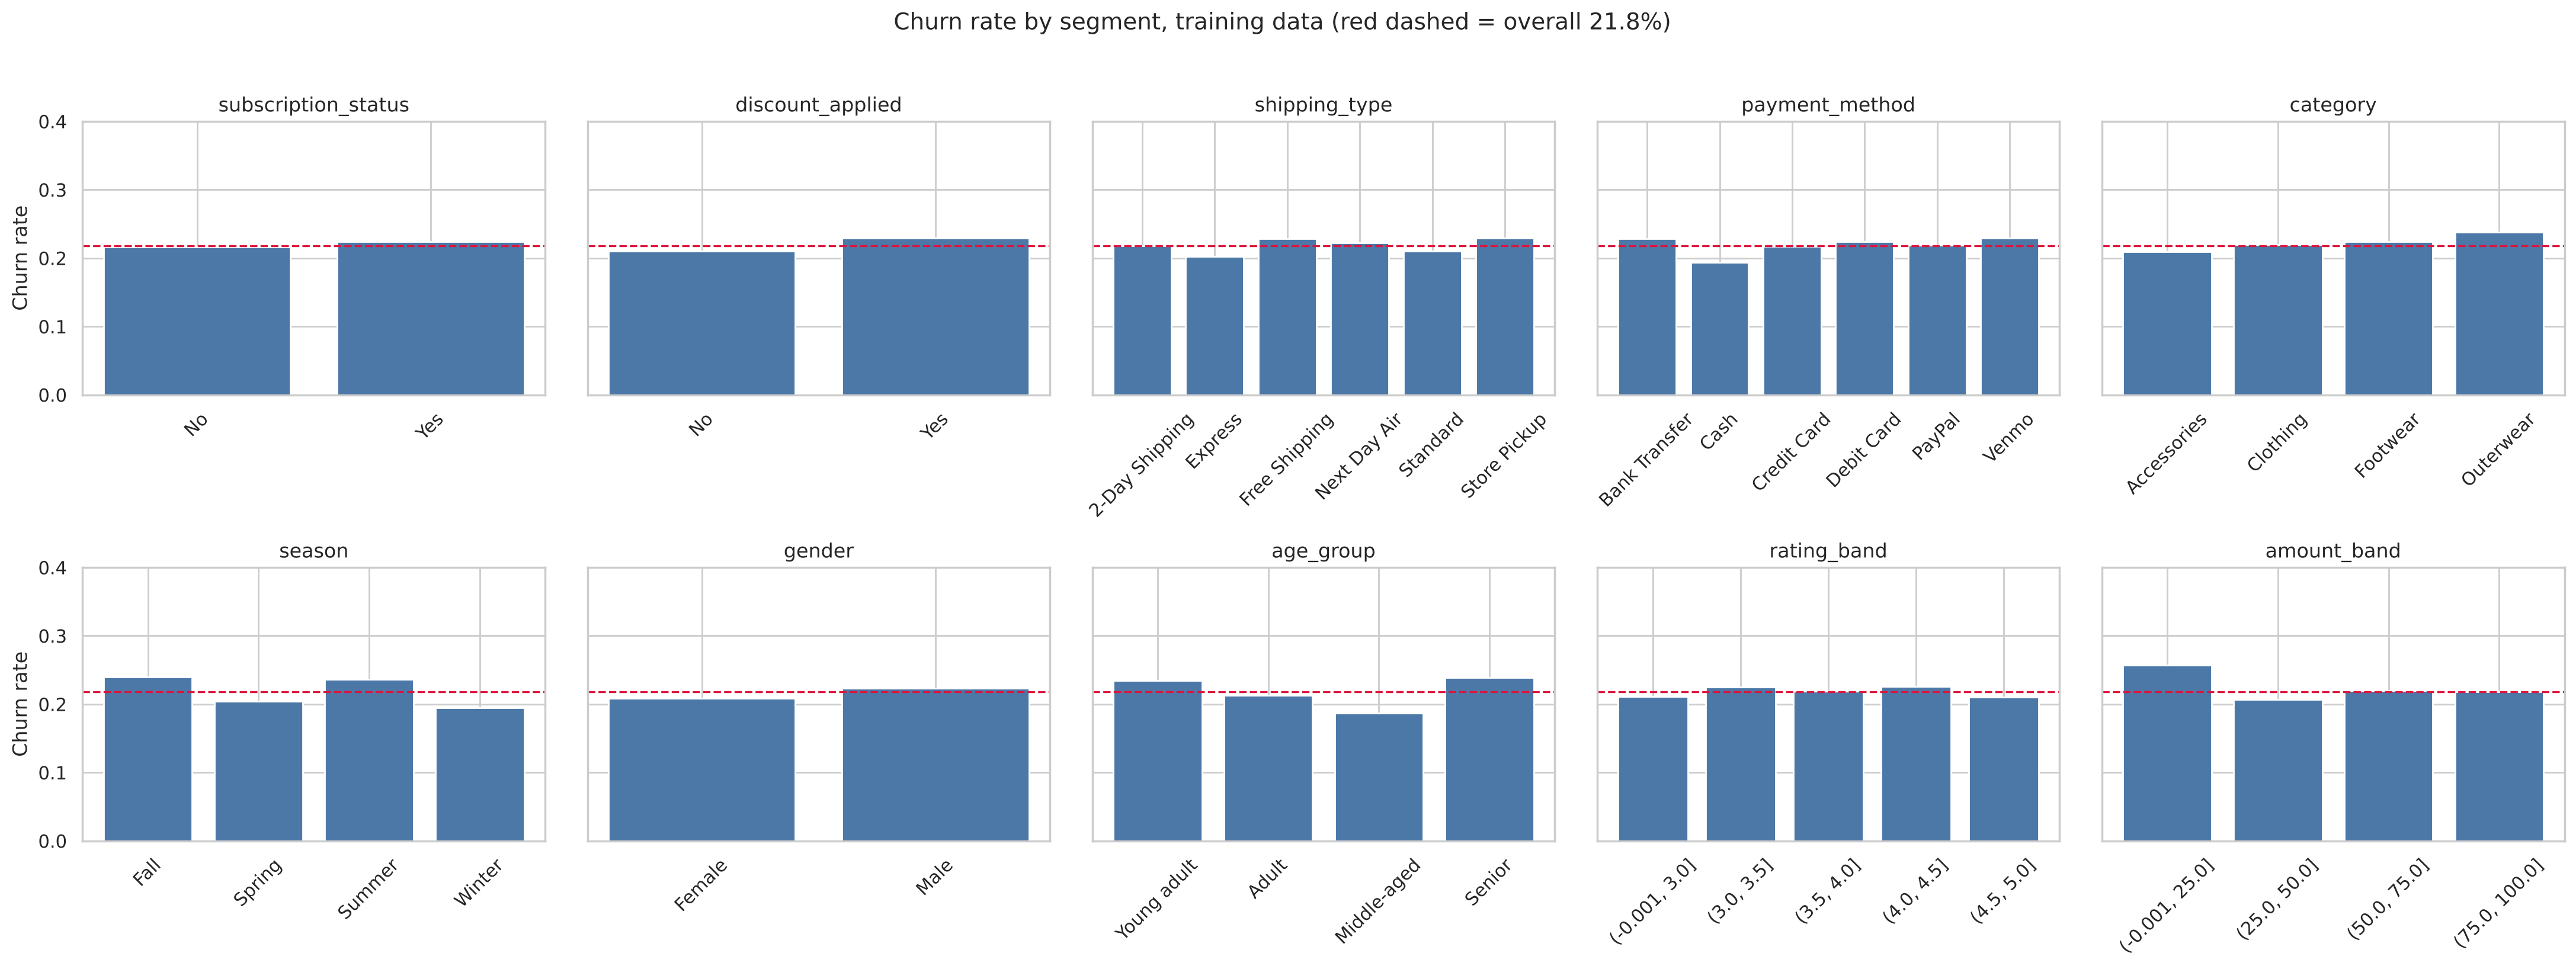

In [5]:
overall = train_df['churn'].mean()
fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharey=True)
for ax, c in zip(axes.ravel(), seg_cols):
    g = train_df.groupby(c, observed=True)['churn'].mean()
    if c == 'age_group':
        g = g.reindex(['Young adult', 'Adult', 'Middle-aged', 'Senior'])
    ax.bar(g.index.astype(str), g.values, color='#4C78A8')
    ax.axhline(overall, color='crimson', ls='--', lw=1.2)
    ax.set_title(c); ax.tick_params(axis='x', rotation=45); ax.set_ylim(0, 0.4)
axes[0, 0].set_ylabel('Churn rate'); axes[1, 0].set_ylabel('Churn rate')
fig.suptitle(f'Churn rate by segment, training data (red dashed = overall {overall:.1%})', y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

## 5. Unsupervised learning — KMeans customer segments (no labels used)
KMeans clusters customers on two engagement signals: purchase interval (log) and previous purchases. (Review rating was tested too, but it is unrelated to the other columns, adds only noise and made the clusters unstable across random seeds, so it is left out.) KMeans is **fit on the training set only**, and test customers are assigned to the nearest cluster. The "at-risk" cluster is picked **without labels** as the one with long intervals *and* few previous purchases; we then check how well it lines up with the churn rule on unseen customers.

In [6]:
def km_features(d):
    return np.column_stack([np.log1p(d['purchase_frequency_days']), d['previous_purchases']])

km_scaler = StandardScaler().fit(km_features(train_df))
Z_train = km_scaler.transform(km_features(train_df))
Z_test  = km_scaler.transform(km_features(test_df))

sil = {k: silhouette_score(Z_train, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z_train))
       for k in range(2, 8)}
print('Silhouette by k:', {k: round(v, 3) for k, v in sil.items()})
print('Silhouette is similar for k=4..7 (interval takes only 7 distinct values); k=4 gives clean, readable groups.')

K = 4
kmeans = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z_train)
train_df['cluster'] = kmeans.labels_
test_df['cluster']  = kmeans.predict(Z_test)

profile = (train_df.groupby('cluster')
           .agg(customers=('customer_id', 'count'),
                avg_interval_days=('purchase_frequency_days', 'mean'),
                avg_previous_purchases=('previous_purchases', 'mean'),
                rule_churn_rate=('churn', 'mean')))
# "At-risk" cluster, chosen WITHOUT labels: long intervals and few previous purchases
z = lambda col: (profile[col] - profile[col].mean()) / profile[col].std()
at_risk_cluster = (z('avg_interval_days') - z('avg_previous_purchases')).idxmax()
profile['label'] = np.where(profile.index == at_risk_cluster, 'AT-RISK', '')
profile.round(2)

Silhouette by k: {2: 0.395, 3: 0.411, 4: 0.464, 5: 0.432, 6: 0.445, 7: 0.465}
Silhouette is similar for k=4..7 (interval takes only 7 distinct values); k=4 gives clean, readable groups.


,customers,avg_interval_days,avg_previous_purchases,rule_churn_rate,label
cluster,,,,,
0,688,188.33,13.01,0.99,AT-RISK
1,672,173.89,38.49,0.00,
2,878,16.19,37.75,0.00,
3,882,16.32,12.80,0.00,


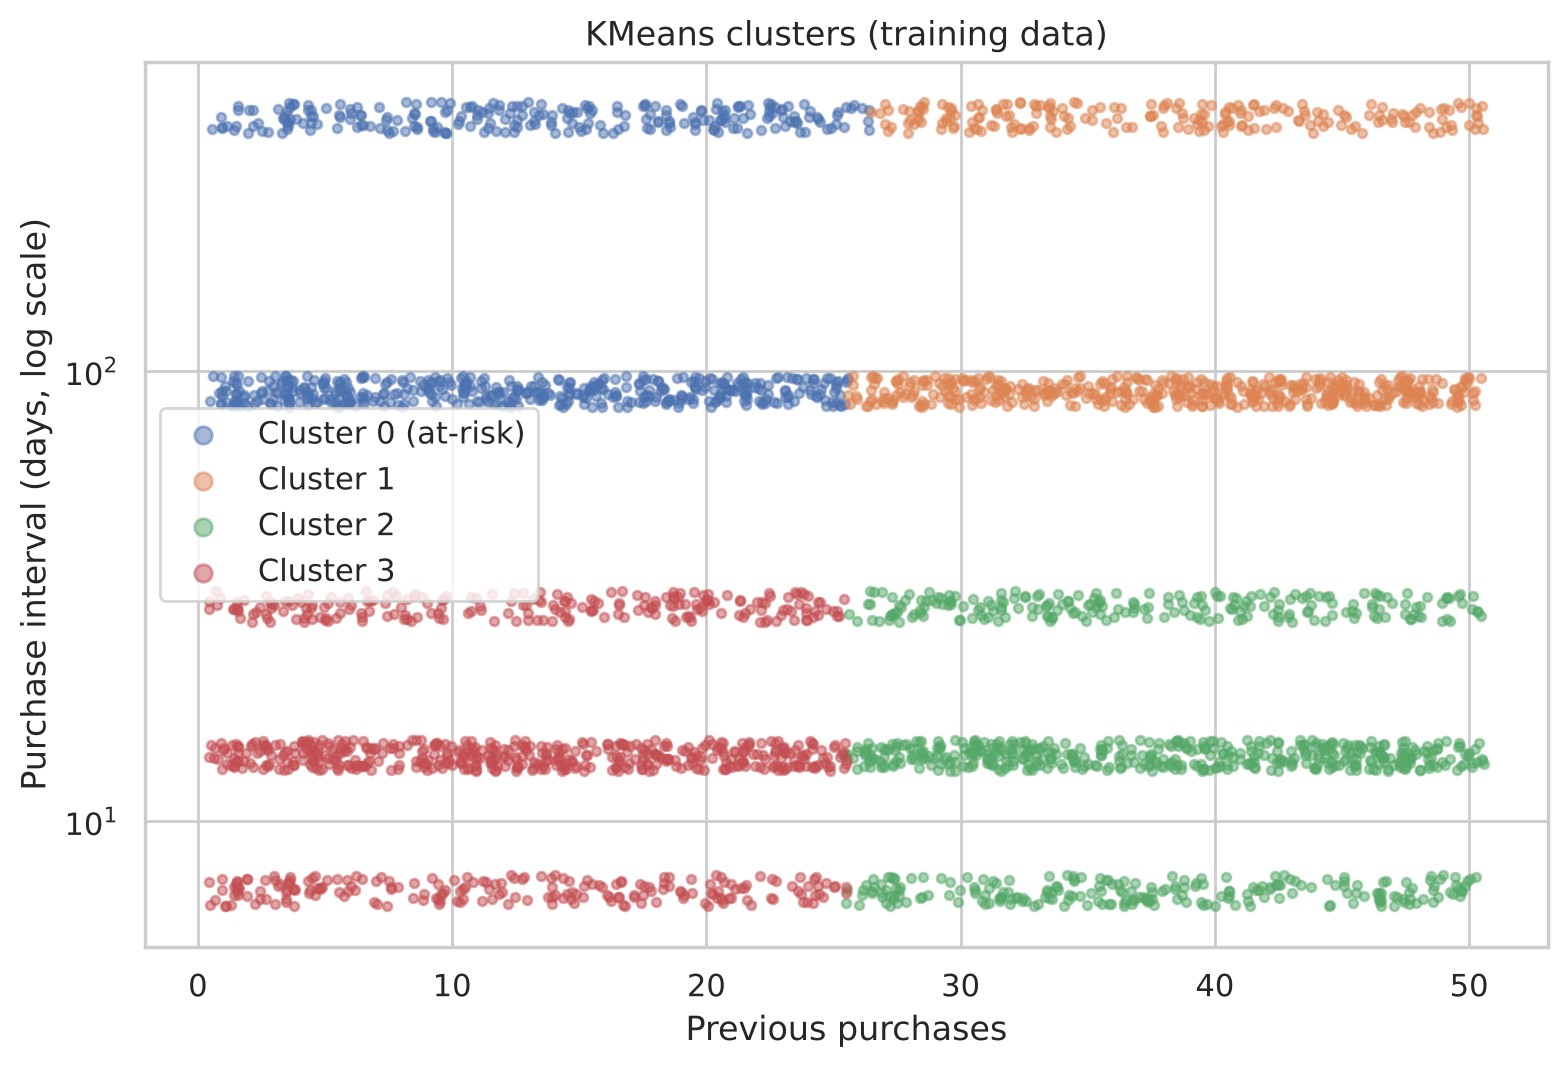

KMeans at-risk cluster (no labels used) vs churn rule, on unseen test customers
  Precision: 0.979   Recall: 1.000   F1: 0.990


In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
rng = np.random.default_rng(RANDOM_STATE)
for cl in sorted(train_df['cluster'].unique()):
    s = train_df[train_df['cluster'] == cl]
    ax.scatter(s['previous_purchases'] + rng.uniform(-.6, .6, len(s)),
               s['purchase_frequency_days'] * np.exp(rng.uniform(-.08, .08, len(s))),
               s=10, alpha=.5, label=f'Cluster {cl}' + (' (at-risk)' if cl == at_risk_cluster else ''))
ax.set_yscale('log'); ax.set(xlabel='Previous purchases', ylabel='Purchase interval (days, log scale)',
                             title='KMeans clusters (training data)')
ax.legend(markerscale=2); plt.tight_layout(); plt.show()

# How well does the label-free at-risk cluster match the churn rule on UNSEEN test customers?
km_pred = (test_df['cluster'] == at_risk_cluster).astype(int)
print('KMeans at-risk cluster (no labels used) vs churn rule, on unseen test customers')
print(f'  Precision: {precision_score(test_df.churn, km_pred):.3f}   '
      f'Recall: {recall_score(test_df.churn, km_pred):.3f}   F1: {f1_score(test_df.churn, km_pred):.3f}')

## 6. Supervised learning — train on labelled training data, evaluate on test customers
- Features: all behavioural + demographic + order columns (the churn rule's own inputs are included, as intended for this version)
- Models, simplest to most complex: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, plus a no-skill Dummy
- 5-fold cross-validation **inside the training set** picks the model; the test set is used once at the end
- If several models tie, the **simplest** one is chosen (easier to explain and audit)

In [8]:
NUM = ['age', 'purchase_amount', 'review_rating', 'previous_purchases', 'purchase_frequency_days']
CAT = ['gender', 'category', 'location', 'season', 'subscription_status',
       'shipping_type', 'discount_applied', 'payment_method', 'age_group']

def prep(d, num, cat):
    X = d[num + cat].copy()
    X[cat] = X[cat].astype(str)
    return X

def make_pipeline(model, num=NUM, cat=CAT):
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
        ('num', StandardScaler(), num)])
    return Pipeline([('pre', pre), ('model', model)])

X_train, y_train = prep(train_df, NUM, CAT), train_df['churn']
X_test,  y_test  = prep(test_df,  NUM, CAT), test_df['churn']

models = {   # ordered simplest -> most complex
    'Dummy (no skill)':    DummyClassifier(strategy='prior'),
    'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced'),
    'Decision Tree':       DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                                                  random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting':   HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                                          class_weight='balanced', random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    pipe = make_pipeline(m)
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    ap  = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision')
    rows.append({'model': name, 'cv_roc_auc': auc.mean(), 'cv_roc_auc_std': auc.std(), 'cv_pr_auc': ap.mean()})
cv_results = pd.DataFrame(rows).set_index('model')

candidates = cv_results.drop('Dummy (no skill)')
best_auc = candidates['cv_roc_auc'].max()
chosen = next(n for n in candidates.index if candidates.loc[n, 'cv_roc_auc'] >= best_auc - 0.005)
print(f'No-skill PR-AUC level = training churn rate = {y_train.mean():.3f}')
print(f'Chosen model (simplest within 0.005 of best CV AUC): {chosen}')
cv_results.round(3)

No-skill PR-AUC level = training churn rate = 0.218
Chosen model (simplest within 0.005 of best CV AUC): Decision Tree


,cv_roc_auc,cv_roc_auc_std,cv_pr_auc
model,,,
Dummy (no skill),0.500,0.000,0.218
Logistic Regression,0.902,0.006,0.764
Decision Tree,1.000,0.000,1.000
Random Forest,1.000,0.000,1.000
Gradient Boosting,1.000,0.000,1.000


Decision Tree on 780 unseen test customers
Test ROC-AUC : 1.000   (95% CI 1.000 - 1.000)
Test PR-AUC  : 1.000   (no-skill level = 0.242)

              precision    recall  f1-score   support

    Retained       1.00      1.00      1.00       591
     Churned       1.00      1.00      1.00       189

    accuracy                           1.00       780
   macro avg       1.00      1.00      1.00       780
weighted avg       1.00      1.00      1.00       780



,test_roc_auc,test_pr_auc,test_f1_at_0.5
model,,,
Dummy (no skill),0.500,0.242,0.000
Logistic Regression,0.898,0.773,0.647
Decision Tree,1.000,1.000,1.000
Random Forest,1.000,1.000,1.000
Gradient Boosting,1.000,1.000,1.000


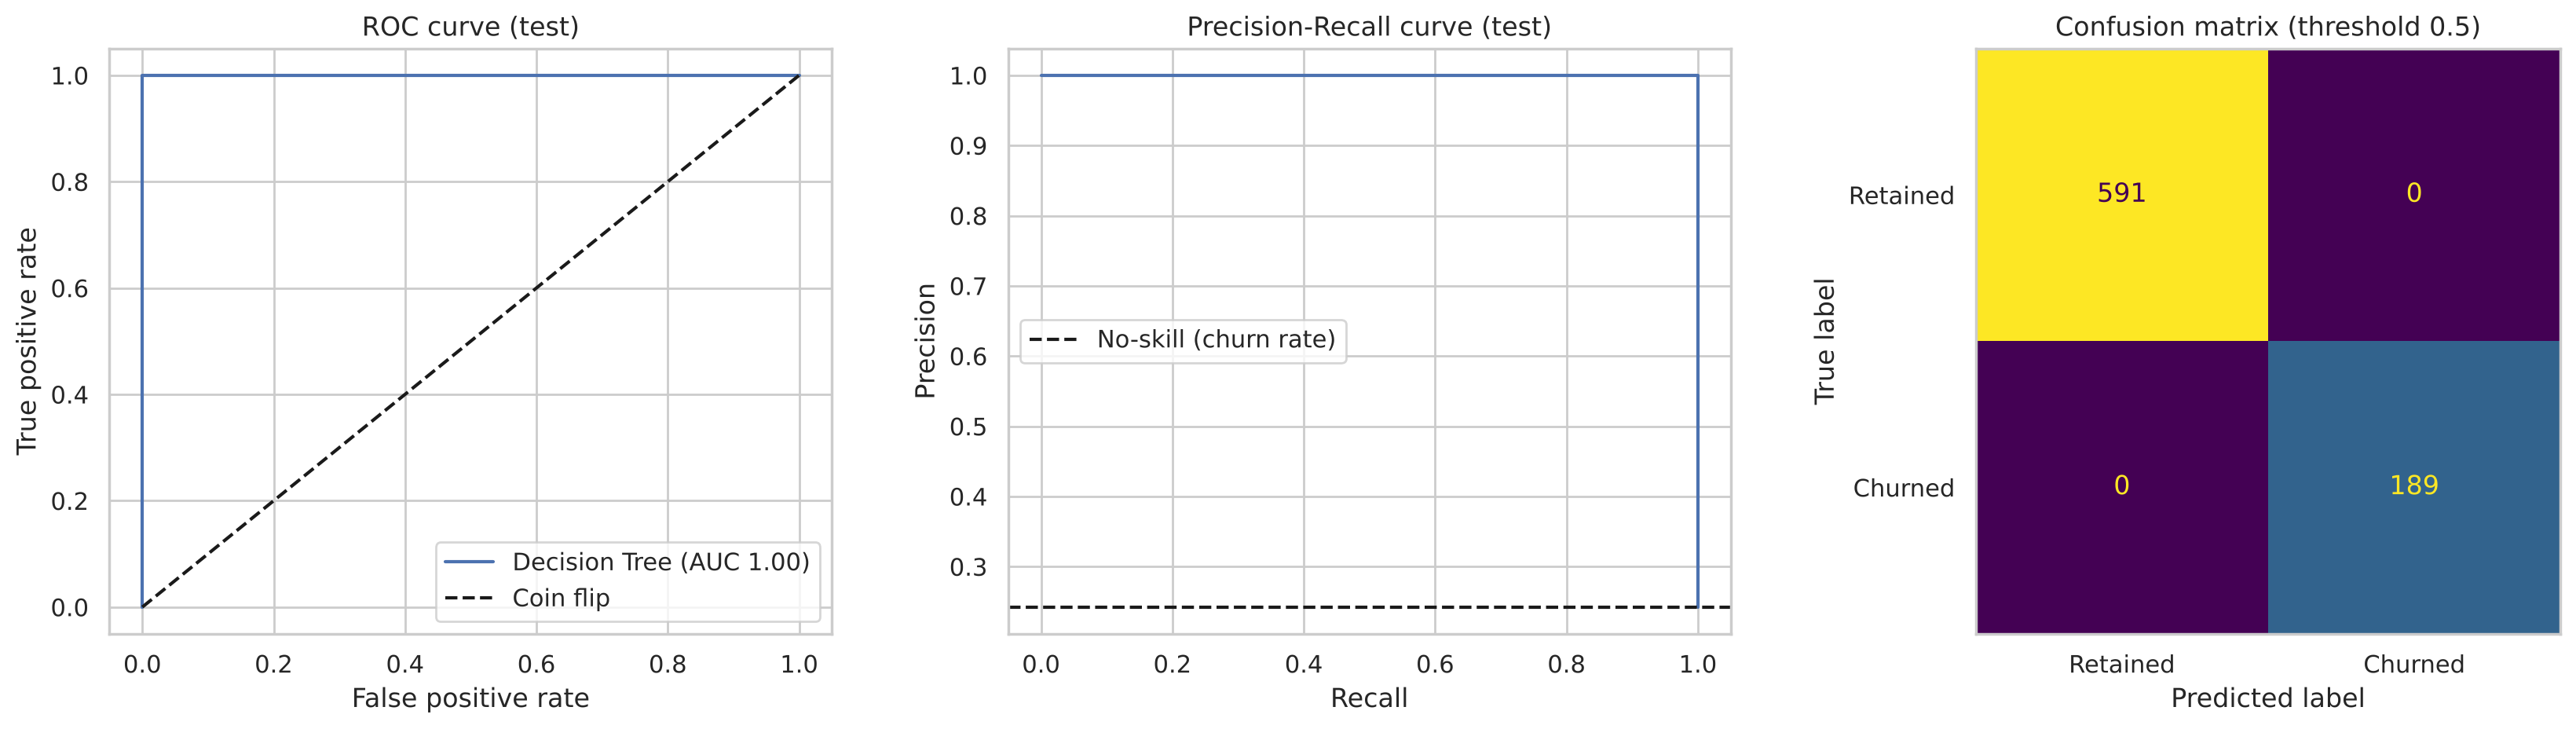

In [9]:
final_pipe = make_pipeline(models[chosen]).fit(X_train, y_train)
proba = final_pipe.predict_proba(X_test)[:, 1]
pred  = (proba >= 0.5).astype(int)

test_auc = roc_auc_score(y_test, proba)
test_ap  = average_precision_score(y_test, proba)

rng = np.random.default_rng(RANDOM_STATE)
yt, boot = y_test.values, []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() != yt[idx].max():
        boot.append(roc_auc_score(yt[idx], proba[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])

print(f'{chosen} on {len(y_test):,} unseen test customers')
print(f'Test ROC-AUC : {test_auc:.3f}   (95% CI {lo:.3f} - {hi:.3f})')
print(f'Test PR-AUC  : {test_ap:.3f}   (no-skill level = {y_test.mean():.3f})\n')
print(classification_report(y_test, pred, target_names=['Retained', 'Churned']))

# every model on the test set, for comparison
cmp_rows = []
for name, m in models.items():
    p = make_pipeline(m).fit(X_train, y_train).predict_proba(X_test)[:, 1]
    cmp_rows.append({'model': name, 'test_roc_auc': roc_auc_score(y_test, p),
                     'test_pr_auc': average_precision_score(y_test, p),
                     'test_f1_at_0.5': f1_score(y_test, (p >= .5).astype(int))})
display(pd.DataFrame(cmp_rows).set_index('model').round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
fpr, tpr, _ = roc_curve(y_test, proba)
axes[0].plot(fpr, tpr, label=f'{chosen} (AUC {test_auc:.2f})'); axes[0].plot([0, 1], [0, 1], 'k--', label='Coin flip')
axes[0].set(title='ROC curve (test)', xlabel='False positive rate', ylabel='True positive rate'); axes[0].legend()
prec, rec, _ = precision_recall_curve(y_test, proba)
axes[1].plot(rec, prec); axes[1].axhline(y_test.mean(), color='k', ls='--', label='No-skill (churn rate)')
axes[1].set(title='Precision-Recall curve (test)', xlabel='Recall', ylabel='Precision'); axes[1].legend()
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Retained', 'Churned'], ax=axes[2], colorbar=False)
axes[2].set_title('Confusion matrix (threshold 0.5)'); axes[2].grid(False)
plt.tight_layout(); plt.show()

## 7. What did the model learn?

,feature,importance,std
0,purchase_frequency_days,0.3554,0.0205
1,previous_purchases,0.3170,0.0174
2,purchase_amount,0.0000,0.0000
3,age,0.0000,0.0000
4,review_rating,0.0000,0.0000
5,gender,0.0000,0.0000
6,category,0.0000,0.0000
7,location,0.0000,0.0000


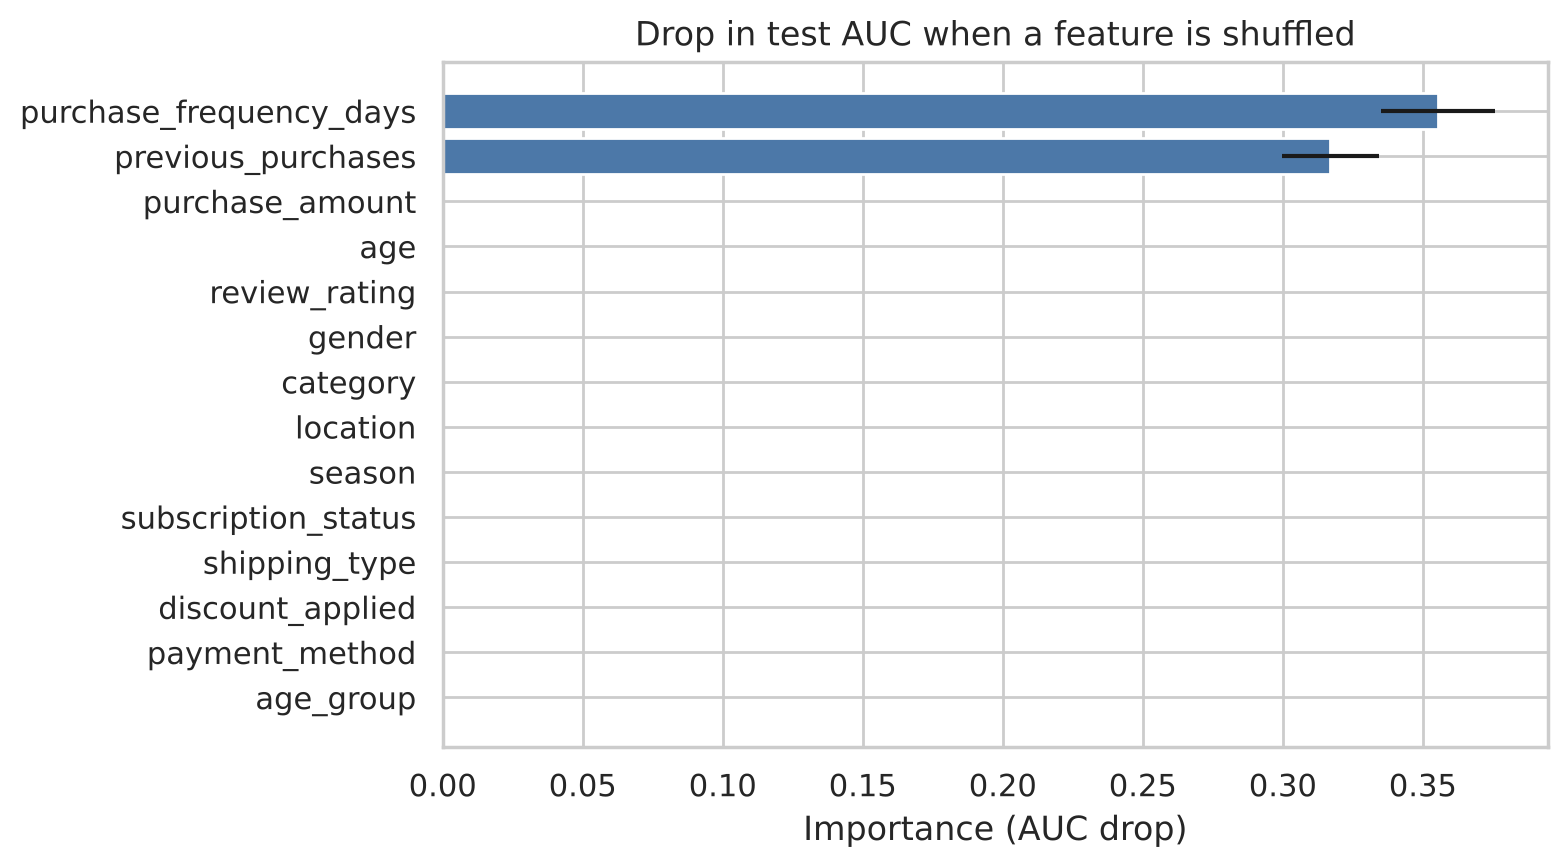

Rule recovered by a depth-2 tree (class 1 = churn):

|--- purchase_frequency_days <= 60.00
|   |--- class: 0
|--- purchase_frequency_days >  60.00
|   |--- previous_purchases <= 25.50
|   |   |--- class: 1
|   |--- previous_purchases >  25.50
|   |   |--- class: 0



In [10]:
perm = permutation_importance(final_pipe, X_test, y_test, scoring='roc_auc',
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({'feature': X_test.columns, 'importance': perm.importances_mean, 'std': perm.importances_std})
         .sort_values('importance', ascending=False).reset_index(drop=True))
display(imp.head(8).round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp['feature'][::-1], imp['importance'][::-1], xerr=imp['std'][::-1], color='#4C78A8')
ax.axvline(0, color='k', lw=0.8)
ax.set(title='Drop in test AUC when a feature is shuffled', xlabel='Importance (AUC drop)')
plt.tight_layout(); plt.show()

# A tiny tree on the two behavioural columns recovers the rule the label was built from
rule_tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE).fit(
    train_df[['purchase_frequency_days', 'previous_purchases']], train_df['churn'])
print('Rule recovered by a depth-2 tree (class 1 = churn):\n')
print(export_text(rule_tree, feature_names=['purchase_frequency_days', 'previous_purchases']))

## 8. Reality check — can anything *other than* the behavioural columns predict churn?
Same train/test setup, but the model **cannot see** `purchase_frequency_days` or `previous_purchases` (the columns that define the label). This asks the real business question: do demographics, product, payment, shipping, subscription, discount or rating tell us who is disengaging?

In [11]:
NUM_BLIND = ['age', 'purchase_amount', 'review_rating']          # no frequency / previous_purchases
Xb_train, Xb_test = prep(train_df, NUM_BLIND, CAT), prep(test_df, NUM_BLIND, CAT)

rows = []
for name in ['Logistic Regression', 'Random Forest', 'Gradient Boosting']:
    pipe = make_pipeline(models[name], NUM_BLIND, CAT)
    cv_auc = cross_val_score(pipe, Xb_train, y_train, cv=cv, scoring='roc_auc').mean()
    p = pipe.fit(Xb_train, y_train).predict_proba(Xb_test)[:, 1]
    rows.append({'model': name, 'cv_roc_auc': cv_auc, 'test_roc_auc': roc_auc_score(y_test, p),
                 'test_pr_auc': average_precision_score(y_test, p)})
blind = pd.DataFrame(rows).set_index('model')
print(f'No-skill: ROC-AUC 0.500, PR-AUC {y_test.mean():.3f}')
blind.round(3)

No-skill: ROC-AUC 0.500, PR-AUC 0.242


,cv_roc_auc,test_roc_auc,test_pr_auc
model,,,
Logistic Regression,0.505,0.510,0.253
Random Forest,0.512,0.509,0.250
Gradient Boosting,0.492,0.506,0.252


## 9. Engagement risk score (rule-based, transparent)
A simple 0–100 score for dashboards, built from percentile ranks across all customers: purchase interval (50%), previous purchases (30%, fewer = riskier), review rating (20%, lower = riskier). **High** = top 20%, **Medium** = next 30%, **Low** = bottom 50%.

In [12]:
scored = (pd.concat([train_df.assign(split='train'), test_df.assign(split='test')])
            .sort_values('customer_id').reset_index(drop=True))

interval_risk = scored['purchase_frequency_days'].rank(pct=True)
history_risk  = 1 - scored['previous_purchases'].rank(pct=True)
rating_risk   = 1 - scored['review_rating'].rank(pct=True)
scored['engagement_risk_score'] = (100 * (0.5 * interval_risk + 0.3 * history_risk + 0.2 * rating_risk)).round(1)

p50, p80 = scored['engagement_risk_score'].quantile([0.50, 0.80])
scored['risk_segment'] = pd.cut(scored['engagement_risk_score'], [-np.inf, p50, p80, np.inf],
                                labels=['Low', 'Medium', 'High'])

summary = (scored.groupby('risk_segment', observed=True)
           .agg(customers=('customer_id', 'count'), avg_risk_score=('engagement_risk_score', 'mean'),
                churn_rate=('churn', 'mean'), avg_purchase_amount=('purchase_amount', 'mean'),
                total_revenue=('purchase_amount', 'sum')))
summary['share_of_revenue'] = summary['total_revenue'] / summary['total_revenue'].sum()
summary.round(3)

,customers,avg_risk_score,churn_rate,avg_purchase_amount,total_revenue,share_of_revenue
risk_segment,,,,,,
Low,1952,35.629,0.000,59.668,116471,0.500
Medium,1173,57.641,0.211,60.260,70685,0.303
High,775,74.629,0.803,59.258,45925,0.197


> **Note:** churn rate by risk segment (0% Low → ~80% High) holds by construction, since the score and the label come from the same signals. It shows the score is consistent with the rule, not independent validation.

## 10. Export for SQL / Power BI
- `ml_churn_probability` — for **test** customers: from the model trained on the training set. For **train** customers: out-of-fold cross-validated probability (each customer scored by a model that never saw them), so no one is scored by a model that memorised them.
- `ml_churn_prediction` — 1 if probability ≥ 0.5
- `kmeans_cluster` / `kmeans_at_risk` — unsupervised segment and its at-risk flag
- `churn_flag` — the rule-based label; `split` — train or test

In [13]:
oof = cross_val_predict(make_pipeline(models[chosen]), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
train_df['ml_churn_probability'] = oof
test_df['ml_churn_probability']  = proba

all_scored = pd.concat([train_df, test_df]).set_index('customer_id')
scored = scored.set_index('customer_id')
scored['ml_churn_probability'] = all_scored['ml_churn_probability'].round(4)
scored['ml_churn_prediction']  = (scored['ml_churn_probability'] >= 0.5).astype(int)
scored['kmeans_cluster']       = all_scored['cluster']
scored['kmeans_at_risk']       = (scored['kmeans_cluster'] == at_risk_cluster).astype(int)
scored['churn_flag']           = scored['churn']

export = scored.reset_index().drop(columns=['churn', 'cluster', 'rating_band', 'amount_band'])
export.to_csv('customer_shopping_churn_scored.csv', index=False)
print(export.shape); print(export.columns.tolist())

try:
    from google.colab import files
    files.download('customer_shopping_churn_scored.csv')
except ImportError:
    print('Saved locally as customer_shopping_churn_scored.csv')

(3900, 27)
['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'previous_purchases', 'payment_method', 'frequency_of_purchases', 'age_group', 'purchase_frequency_days', 'split', 'engagement_risk_score', 'risk_segment', 'ml_churn_probability', 'ml_churn_prediction', 'kmeans_cluster', 'kmeans_at_risk', 'churn_flag']
Saved locally as customer_shopping_churn_scored.csv


## Findings

**Setup:** 3,120 train / 780 test customers; churn rule (interval ≥ 90 days and ≤ 25 previous purchases, cut-off learned on train) flags 21.8% of train and 24.2% of test.

**Supervised ML:** Decision Tree, Random Forest and Gradient Boosting all score ROC-AUC 1.00 on the 780 unseen test customers; Logistic Regression scores about 0.90 (the rule is an AND of two thresholds, which a straight-line boundary can't fit). The simplest tied model, the Decision Tree, was chosen, and it recovers the rule exactly (> 60 days and ≤ 25.5 previous purchases). Permutation importance puts all the weight on purchase interval and previous purchases; every other column is exactly zero.

**Unsupervised ML:** KMeans (k = 4) on interval and history alone, with no labels, finds an at-risk cluster that matches the churn rule on unseen test customers (precision 0.98, recall 1.00; the training cluster has a 99% rule-churn rate vs 0% for the other three).

**Reality check (section 8):** without the two behavioural columns, every model scores ROC-AUC ≈ 0.50 on the test set, which is a coin flip. Demographics, product, payment, shipping, subscription, discount, rating and order value carry no usable information about who is disengaging. In the segment table, one column (age group, p = 0.046) looks significant, but that is expected by chance when running 10 tests, and it does not hold on the full dataset (p ≈ 0.10).

**What this means:** the ML model is a working, auditable *churn-flag classifier* — it scores any new customer from their purchase behaviour, and the notebook runs the full train, test and export flow. Its near-perfect accuracy comes from the label being defined by the same columns, so it should not be presented as forecasting *future* churn from independent signals. That would need real outcomes, such as dated transactions showing who stopped buying.